In [1]:
import sys
import warnings
from pathlib import Path

warnings.filterwarnings("ignore")
# Permite importar tu paquete de src/ sin instalarlo
sys.path.insert(0, str(Path.cwd().resolve().parent / "src"))


# 05 · Torneo de modelos

> **Esqueleto.** Guía completa: `curso/kit-estudiante/guia-modelado-y-optimizacion.md`, sección 2.

Objetivo: elegir **uno o dos finalistas** para optimizar, con evidencia y sin abrir la prueba. Reglas:

1. **Mismos datos y mismos pliegues** para todos (por entidad si hay entidades repetidas).
2. Una **línea base** que cualquier modelo serio debe vencer.
3. **Guardar cada pliegue**, no solo el promedio, para comparar de a pares.

El torneo **descarta**, no corona: la optimización puede cambiar el orden y solo la prueba final (clase 4)
dice qué tan bueno es el modelo elegido.

## 0. Cargar los datos de entrenamiento

In [2]:
import pandas as pd

from proyecto.models.train import TARGET   # "punt_global"

# === Configuración (la misma de los notebooks 03 y 04) ===
ID_COL = "cole_cod_dane_sede"   # sede del colegio: la entidad que se repite (decisión 10 del EDA)

train_path = Path.cwd().resolve().parent / "data" / "processed" / "train.joblib"
if not train_path.exists():
    train = None
    print("Todavía no hay datos de entrenamiento: completa y ejecuta antes el notebook 03_preprocesamiento.")
else:
    import joblib
    train = joblib.load(train_path)
    print(f"entrenamiento: {train.shape[0]:,} filas x {train.shape[1]} columnas (la prueba NO se abre hoy)")

listo = train is not None and TARGET is not None

entrenamiento: 57,286 filas x 36 columnas (la prueba NO se abre hoy)


## 1. Validación común (los mismos pliegues para todos)

In [3]:
if not listo:
    pliegues = None
    print("Sin datos: esta celda crea los pliegues cuando estén.")
else:
    from proyecto.data.split import GROUP_COL, group_cv
    from proyecto.models.train import feature_frame

    assert GROUP_COL == ID_COL
    X, y = feature_frame(train)   # X conserva la sede solo para agrupar; el preprocesador la descarta
    cv = group_cv(n_splits=5)     # GroupKFold por sede: no baraja, así que da siempre los mismos pliegues
    pliegues = list(cv.split(X, y, groups=X[ID_COL]))
    assert all((a == c).all() and (b == d).all()
               for (a, b), (c, d) in zip(pliegues, cv.split(X, y, groups=X[ID_COL]))), "los pliegues cambiaron"
    for i_ent, i_val in pliegues:   # comprobación: ninguna sede en los dos lados de un pliegue
        assert set(X.iloc[i_ent][ID_COL]).isdisjoint(set(X.iloc[i_val][ID_COL])), "hay sedes en los dos lados"
    print(f"{len(pliegues)} pliegues por sede, los MISMOS para todos los candidatos.")
    print("estudiantes de validación por pliegue:", [len(i_val) for _, i_val in pliegues])

5 pliegues por sede, los MISMOS para todos los candidatos.
estudiantes de validación por pliegue: [11458, 11457, 11457, 11457, 11457]


## 2. Pipeline y métricas

Reporta **dos familias de métricas**, siempre las dos (guía, sección 2.2):

- **De negocio (la principal):** refleja la decisión del negocio y decide quién gana.
- **Técnicas:** AUC macro y de la clase de interés, PR-AUC, exactitud balanceada, precisión y recall **por clase**,
  F1 macro y log loss (en regresión: RMSE, MAE y R²). No dependen del negocio y muestran lo que la métrica de
  negocio puede esconder, por ejemplo una clase que casi nunca se predice.

No uses la exactitud simple si las clases están desbalanceadas: usa la exactitud balanceada.

In [4]:
from proyecto.models.train import build_pipeline, candidates, evaluate_folds

# Métricas de regresión, calculadas igual para todos por `evaluate_folds` (regression_metrics):
#   MAE (principal, la del negocio), RMSE y R² (técnicas), todas en positivo, más los segundos de ajuste.
# `scoring()` (MAE y RMSE negativos) queda para la búsqueda de la etapa 6.
METRICA = "mae"
TECNICAS = ["rmse", "r2"]
META_MINIMA, META_DESEABLE = 38.0, 35.0   # especificacion-proyecto.md, sección 4

## 3. Candidatos

Mínimo **3 modelos y una línea base**: algo simple e interpretable, un bosque y un modelo de boosting.

In [5]:
# Los 5 candidatos aprobados por el grupo con sus parámetros de partida (specs/003-model-training/research.md §2).
# LightGBM se reemplazó por HistGradientBoosting (decisión del grupo, 31 oct 2026).
candidatos = candidates()   # nombre -> (modelo sin ajustar, ¿escalar?)
for nombre, (modelo, escalar) in candidatos.items():
    print(f"{nombre:24s} escalar={escalar!s:5s} {modelo}")

línea base (mediana)     escalar=False DummyRegressor(strategy='median')
ridge                    escalar=True  Ridge()
random forest            escalar=False RandomForestRegressor(min_samples_leaf=3, n_estimators=200, n_jobs=2,
                      random_state=42)
hist gradient boosting   escalar=False HistGradientBoostingRegressor(early_stopping=False, learning_rate=0.05,
                              max_iter=300, random_state=42)
xgboost                  escalar=False XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=None, device=None, early_stopping_rounds=None,
             enable_categorical=True, eval_metric=None, feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=0.05, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_

## 4. Correr el torneo (una fila por pliegue)

In [6]:
import time

por_pliegue = {}   # nombre del modelo -> DataFrame con una fila por pliegue (mae, rmse, r2, fit_seconds)

if not pliegues:
    print("Pendiente: datos y pliegues para correr el torneo.")
else:
    for nombre, (modelo, escalar) in candidatos.items():
        # Variables base: use_engineered=False y min_frequency 1 % (reports/04_features.md).
        pipeline = build_pipeline(modelo, scale=escalar, use_engineered=False, min_frequency=0.01)
        inicio = time.time()
        por_pliegue[nombre] = evaluate_folds(pipeline, X, y, cv)
        print(f"{nombre:24s} listo ({time.time() - inicio:,.0f} s en total)")

    tabla_pliegues = pd.concat(por_pliegue, names=["modelo"])
    display(tabla_pliegues.round(3))

línea base (mediana)     listo (9 s en total)


ridge                    listo (8 s en total)


random forest            listo (268 s en total)


hist gradient boosting   listo (42 s en total)


xgboost                  listo (18 s en total)


mae    rmse     r2  fit_seconds
modelo                 fold                                    
línea base (mediana)   0     43.185  52.517 -0.040        1.758
                       1     43.050  51.657 -0.000        1.538
                       2     42.847  51.517 -0.001        1.450
                       3     43.256  52.472 -0.015        1.367
                       4     41.791  50.406 -0.000        1.369
ridge                  0     34.699  42.897  0.306        1.764
                       1     34.929  43.000  0.307        1.324
                       2     35.034  43.071  0.300        1.357
                       3     34.501  42.343  0.339        1.412
                       4     34.716  42.782  0.280        1.382
random forest          0     34.882  43.470  0.288       46.415
                       1     34.739  42.781  0.314       46.583
                       2     35.167  43.546  0.285       57.310
                       3     34.425  42.537  0.333       58.819
                       4     34.513  42.836  0.278       56.545
hist gradient boosting 0     33.614  41.804  0.341        8.908
                       1     33.637  41.441  0.356        7.748
                       2     33.900  41.847  0.339        7.914
                       3     33.400  41.183  0.375        7.309
                       4     33.264  41.199  0.332        7.359
xgboost                0     33.664  41.837  0.340        3.550
                       1     33.665  41.523  0.354        3.545
                       2     33.941  41.908  0.338        3.365
                       3     33.667  41.491  0.365        3.050
                       4     33.351  41.338  0.327        3.122

## 5. Tabla resumen y variabilidad

,MAE (media),± entre pliegues,segundos de ajuste,mejora vs línea base (puntos),mejora vs línea base (%),meta mínima (≤ 38),meta deseable (≤ 35)
hist gradient boosting,33.563,0.244,7.848,9.263,21.629,True,True
xgboost,33.657,0.209,3.327,9.168,21.408,True,True
random forest,34.745,0.297,53.135,8.080,18.868,True,True
ridge,34.776,0.209,1.448,8.050,18.797,True,True
línea base (mediana),42.826,0.599,1.496,0.000,0.000,False,False


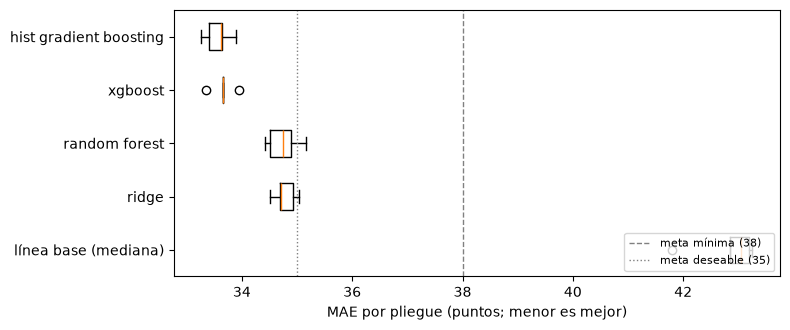

In [7]:
import numpy as np

if not por_pliegue:
    print("Sin resultados todavía: esta celda mostrará la media ± desviación de cada modelo.")
else:
    resumen = pd.DataFrame({
        nombre: {"MAE (media)": f[METRICA].mean(), "± entre pliegues": f[METRICA].std(ddof=1),
                 "segundos de ajuste": f["fit_seconds"].mean()}
        for nombre, f in por_pliegue.items()
    }).T.sort_values("MAE (media)")   # menor MAE es mejor

    base = resumen.loc["línea base (mediana)", "MAE (media)"]
    resumen["mejora vs línea base (puntos)"] = base - resumen["MAE (media)"]
    resumen["mejora vs línea base (%)"] = 100 * resumen["mejora vs línea base (puntos)"] / base
    resumen["meta mínima (≤ 38)"] = resumen["MAE (media)"] <= META_MINIMA
    resumen["meta deseable (≤ 35)"] = resumen["MAE (media)"] <= META_DESEABLE
    display(resumen.round(3))

    import matplotlib.pyplot as plt
    orden = list(resumen.index)
    fig, ax = plt.subplots(figsize=(8, 3.4))
    ax.boxplot([por_pliegue[n][METRICA] for n in orden], vert=False, tick_labels=orden, widths=0.5)
    ax.axvline(META_MINIMA, ls="--", color="gray", lw=1, label="meta mínima (38)")
    ax.axvline(META_DESEABLE, ls=":", color="gray", lw=1, label="meta deseable (35)")
    ax.invert_yaxis()
    ax.set_xlabel("MAE por pliegue (puntos; menor es mejor)")
    ax.legend(loc="lower right", fontsize=8)
    plt.tight_layout()
    plt.show()

### 5.1 Métricas técnicas (no solo la de negocio)

El MAE dice cuántos puntos se equivoca el modelo en un estudiante típico. Las **técnicas de regresión** (guía, sección
2.2) muestran lo que el MAE puede esconder:

- **RMSE:** castiga más los errores grandes. Si dos modelos tienen MAE parecido y RMSE distinto, uno de ellos comete
  más errores grandes (estudiantes a los que les estima muy mal el puntaje).
- **RMSE / MAE:** cuánto pesan los errores grandes (cuanto más alto, más dispersos los errores).
- **R²:** qué parte de la variación del puntaje explica el modelo (0 = lo mismo que predecir la media; negativo = peor).
- **Error relativo:** MAE ÷ puntaje medio de entrenamiento.

Las preguntas de clasificación de la plantilla (AUC, recall por clase, clase sacrificada) no aplican a regresión; se
reemplazan por estas.

In [8]:
if not por_pliegue:
    tecnicas = None
    print("Sin resultados todavía.")
else:
    tecnicas = pd.DataFrame({
        nombre: {"MAE": f["mae"].mean(), "RMSE": f["rmse"].mean(), "± RMSE": f["rmse"].std(ddof=1),
                 "R²": f["r2"].mean(), "± R²": f["r2"].std(ddof=1),
                 "RMSE / MAE": (f["rmse"] / f["mae"]).mean(),
                 "error relativo (%)": 100 * f["mae"].mean() / y.mean()}
        for nombre, f in por_pliegue.items()
    }).T.loc[resumen.index]
    print(f"puntaje medio de entrenamiento: {y.mean():.1f}")
    display(tecnicas.round(3))

puntaje medio de entrenamiento: 246.4


,MAE,RMSE,± RMSE,R²,± R²,RMSE / MAE,error relativo (%)
hist gradient boosting,33.563,41.495,0.319,0.349,0.017,1.236,13.622
xgboost,33.657,41.619,0.243,0.345,0.015,1.237,13.660
random forest,34.745,43.034,0.448,0.299,0.023,1.239,14.102
ridge,34.776,42.819,0.287,0.306,0.021,1.231,14.114
línea base (mediana),42.826,51.714,0.862,-0.011,0.017,1.208,17.381


### 5.2 ¿Coinciden los rankings de negocio y técnico?

Posición de cada modelo (1 = mejor) por MAE (negocio), RMSE (errores grandes) y R² (variación explicada). Si el mejor por
MAE no es el mejor por RMSE, gana en el error típico pero comete más errores grandes.

In [9]:
if tecnicas is None:
    print("Cuando tengas `resumen` y `tecnicas`, compara aquí las posiciones de cada modelo en cada métrica.")
else:
    posiciones = pd.DataFrame({
        "MAE (negocio)": tecnicas["MAE"].rank(method="min"),
        "RMSE": tecnicas["RMSE"].rank(method="min"),
        "R²": tecnicas["R²"].rank(method="min", ascending=False),
        "segundos de ajuste": resumen["segundos de ajuste"].rank(method="min"),
    }).astype(int)
    display(posiciones)

    mejor_mae = tecnicas["MAE"].idxmin()
    print(f"mejor por MAE:  {mejor_mae}")
    print(f"mejor por RMSE: {tecnicas['RMSE'].idxmin()}  -> ¿coincide? {tecnicas['RMSE'].idxmin() == mejor_mae}")
    print(f"mejor por R²:   {tecnicas['R²'].idxmax()}  -> ¿coincide? {tecnicas['R²'].idxmax() == mejor_mae}")
    print("¿algún modelo con R² ≤ 0 (no mejor que predecir la media)?:",
          list(tecnicas.index[tecnicas["R²"] <= 0]) or "ninguno")

,MAE (negocio),RMSE,R²,segundos de ajuste
hist gradient boosting,1,1,1,4
xgboost,2,2,2,3
random forest,3,4,4,5
ridge,4,3,3,1
línea base (mediana),5,5,5,2


mejor por MAE:  hist gradient boosting
mejor por RMSE: hist gradient boosting  -> ¿coincide? True
mejor por R²:   hist gradient boosting  -> ¿coincide? True
¿algún modelo con R² ≤ 0 (no mejor que predecir la media)?: ['línea base (mediana)']


**Mis conclusiones sobre las métricas técnicas** (adaptadas a regresión):

- **¿El mejor por MAE también es el mejor por RMSE y por R²?** Sí. HistGradientBoosting es 1.º en las tres (MAE 33,56,
  RMSE 41,50, R² 0,349) y XGBoost 2.º en las tres (33,66 / 41,62 / 0,345). Ganar en MAE no se logra a costa de más
  errores grandes.
- **¿Hay modelos con MAE casi igual y RMSE distinto?** Sí: Random Forest y Ridge empatan en MAE (34,75 y 34,78), pero
  Random Forest tiene peor RMSE (43,03 frente a 42,82) y peor R² (0,299 frente a 0,306): comete algo más de errores
  grandes. La razón RMSE / MAE es casi igual en los cuatro modelos (1,23–1,24): ninguno concentra errores extremos.
- **¿Algún modelo no explica nada?** Solo la línea base (R² −0,011, como se espera de predecir la mediana). Los modelos
  explican entre el 30 % y el 35 % de la variación del puntaje: el resto depende de cosas que la app no pregunta.
- **¿Qué implica para el negocio?** El error típico baja de ±42,8 a ±33,6 puntos (21,6 % menos); aun así es un error de
  ~14 % del puntaje medio, así que la estimación orienta, no clasifica a nadie.

## 6. Comparación pareada

Como todos se evaluaron en **los mismos pliegues**, puedes comparar pliegue a pliegue: ¿gana siempre el mismo?

In [10]:
def comparar(mejor, otro):
    """Ambos: valores por pliegue (menor es mejor). 'diferencia' positiva: 'mejor' gana."""
    dif = np.asarray(otro) - np.asarray(mejor)
    ruido = dif.std(ddof=1)
    return {
        "diferencia media": dif.mean(),
        "pliegues que gana": f"{(dif > 0).sum()} de {len(dif)}",
        "diferencia / ruido": dif.mean() / ruido if ruido > 0 else np.inf,
    }


if not por_pliegue or len(por_pliegue) < 2:
    print("Sin resultados todavía: aquí se comparan de a pares los mejores modelos.")
else:
    # El mejor por MAE contra cada uno de los demás, y los dos siguientes entre sí (mismos pliegues para todos).
    orden = list(resumen.index)
    pares = [(orden[0], otro) for otro in orden[1:]] + [(orden[1], orden[2])]
    filas = []
    for metrica in [METRICA, "rmse"]:
        for a, b in pares:
            filas.append({"métrica": metrica, "mejor": a, "contra": b,
                          **comparar(por_pliegue[a][metrica], por_pliegue[b][metrica])})
    comparacion = pd.DataFrame(filas)
    display(comparacion.round(3))

,métrica,mejor,contra,diferencia media,pliegues que gana,diferencia / ruido
0,mae,hist gradient boosting,xgboost,0.095,5 de 5,0.955
1,mae,hist gradient boosting,random forest,1.182,5 de 5,10.567
2,mae,hist gradient boosting,ridge,1.213,5 de 5,7.739
3,mae,hist gradient boosting,línea base (mediana),9.263,5 de 5,17.579
4,mae,xgboost,random forest,1.088,5 de 5,5.611
5,rmse,hist gradient boosting,xgboost,0.125,5 de 5,1.137
6,rmse,hist gradient boosting,random forest,1.539,5 de 5,8.692
7,rmse,hist gradient boosting,ridge,1.324,5 de 5,5.737
8,rmse,hist gradient boosting,línea base (mediana),10.219,5 de 5,12.406
9,rmse,xgboost,random forest,1.415,5 de 5,5.497


## 7. ¿Cuánto vale la diferencia?

No hay dinero en juego: se traduce a **puntos de error y estudiantes**. La prueba Saber 11 es anual, así que el volumen es
la cohorte de un año: 72.148 estudiantes de calendario A en Antioquia en 2022 (tras limpiar, notebook 03).

In [11]:
ESTUDIANTES_AL_AÑO = 72_148   # cohorte 2022 tras la limpieza de la etapa 3 (no es una estimación)

if not por_pliegue:
    print("Corre el torneo para ver el valor de la diferencia.")
else:
    valor = pd.DataFrame({
        "MAE (puntos por estudiante)": resumen["MAE (media)"],
        "puntos de error ahorrados por estudiante vs línea base": resumen["mejora vs línea base (puntos)"],
        "puntos de error ahorrados en la cohorte vs línea base": resumen["mejora vs línea base (puntos)"] * ESTUDIANTES_AL_AÑO,
    })
    display(valor.style.format("{:,.2f}"))
    a, b = resumen.index[:2]
    dif = resumen.loc[b, "MAE (media)"] - resumen.loc[a, "MAE (media)"]
    print(f"diferencia entre el mejor ({a}) y el siguiente ({b}): {dif:.3f} puntos por estudiante")

,MAE (puntos por estudiante),puntos de error ahorrados por estudiante vs línea base,puntos de error ahorrados en la cohorte vs línea base
hist gradient boosting,33.56,9.26,"668,283.36"
xgboost,33.66,9.17,"661,465.16"
random forest,34.75,8.08,"582,970.94"
ridge,34.78,8.05,"580,785.95"
línea base (mediana),42.83,0.00,0.00


diferencia entre el mejor (hist gradient boosting) y el siguiente (xgboost): 0.095 puntos por estudiante


## 8. Finalistas

**1 o 2**, mirando en este orden: consistencia entre pliegues, métrica principal, tiempo de ajuste y
simplicidad, e interpretabilidad si tu caso la exige.

| Finalista | Por qué | Qué podría cambiar con la optimización |
|---|---|---|
| HistGradientBoosting | Mejor MAE (33,56 ± 0,24), RMSE y R²; gana a Random Forest y a Ridge en 5 de 5 pliegues con diferencias de 10,6 y 7,7 veces el ruido | Pérdida de error absoluto (`loss="absolute_error"`), tasa de aprendizaje, número de hojas e iteraciones; umbral `min_frequency` 0,1 % |
| XGBoost | Empate práctico con HistGradientBoosting (0,095 puntos, 0,95 veces el ruido) y 2,4 veces más rápido (3,3 s frente a 7,8 s por ajuste); gana a Random Forest en 5 de 5 con 5,6 veces el ruido | Pérdida `reg:absoluteerror`, profundidad, tasa de aprendizaje, regularización; umbral `min_frequency` 0,1 % |

**Descartados:** Random Forest (1,18 puntos peor que el mejor y el más lento: 53 s por ajuste); Ridge (1,21 puntos peor;
el más rápido e interpretable, pero el caso no exige interpretabilidad por regulación y la diferencia es consistente);
línea base (42,83, no cumple la meta).

**Por qué el torneo no elige un campeón:** los dos boosting están empatados dentro del ruido (gana HistGradientBoosting en
los 5 pliegues, pero por menos de una desviación), y la optimización de la etapa 6 puede cambiar ese orden. Además, todo
se midió con validación; solo la prueba final (etapa 7) dirá qué tan bien funciona el modelo elegido con colegios nuevos.

## Entregable de esta etapa

- [x] Al menos **3 modelos y una línea base**, evaluados en **los mismos pliegues**.
- [x] Una fila **por pliegue** guardada para cada modelo.
- [x] **Métricas técnicas** de cada modelo (en regresión: RMSE, R², RMSE / MAE y error relativo) y la comparación entre el ranking de negocio y el técnico.
- [x] Comparación pareada de los mejores (pliegues que gana y diferencia / ruido).
- [x] La diferencia traducida a **volumen** (puntos de error y estudiantes).
- [x] **1–2 finalistas** justificados en `reports/05_torneo.md`.
- [x] El código reutilizable está en `src/proyecto/models/` y el notebook solo lo llama.